# Pre-flight check for the 30-seed `turbulence_final` launch

Loads the data and builds the potentials **exactly as `run_SDE.py` will do them** for the planned production run (n1=10000, nt=55000, two_phase, M=256, J=8, Q=3, L_6_psi dropped, `--drop_stats Scalar_morlet_gaussianK:8:1`). No SDE loop — this is a lightweight cautious check before committing 30 jobs.

Inspect in order:
1. Data shape and marginal (should be ~N(0,1) in bulk after `normalize`, heavier tails).
2. A few sample time series.
3. Scaling-exponent ratio (confirms turbulent scaling).
4. Filters built at the production (M, J, Q).
5. The exact potential set that will enter the Gram, with `--drop_stats` applied.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import sys
from pathlib import Path

root = Path.cwd()
sys.path.insert(0, str(root / '../codes'))
from sde_routines import SDE
from potentials_builder import get_1d_potentials
from filters_bank import return_Filters
from utils import normalize, split_periodize_reshape
from ortho_wavelet import DefineWavelet
from check_moments import plot_time_series_row, scaling_exponent_ratio_compare

sys.path.insert(0, str(root / '../data'))
from data_loader import load_turbulence_1d

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## Production config (edit here only if the launcher changes)

In [2]:
N1              = 10000
SUBSERIES_LEN   = 512
TARGET_LEN      = 256
J               = 8
Q               = 3
DEDUP_TOL       = 1e-8
TERMS = [
    'L_6', 'L_2_lowpass',
    'Scalar_psi_gaussianK', 'Scalar_morlet_gaussianK',
    'Scattering_Fourth_Order_Mod2_Real_Q1',
    'Scattering_Fourth_Order_Mod2_Imag_Q1',
]  # L_6_psi omitted on purpose (preflight: 2 near-perfect copies with L_6 at coarsest scales)
DROP_STATS = [('Scalar_morlet_gaussianK', 8, 1)]  # NAME, channel, region
print(f'N1={N1}, subseries_len={SUBSERIES_LEN}, target_len={TARGET_LEN}, J={J}, Q={Q}')
print('terms:', TERMS)
print('drop_stats:', DROP_STATS)

N1=10000, subseries_len=512, target_len=256, J=8, Q=3
terms: ['L_6', 'L_2_lowpass', 'Scalar_psi_gaussianK', 'Scalar_morlet_gaussianK', 'Scattering_Fourth_Order_Mod2_Real_Q1', 'Scattering_Fourth_Order_Mod2_Imag_Q1']
drop_stats: [('Scalar_morlet_gaussianK', 8, 1)]


## Data loading (identical to `run_SDE.py` without `--n1_spread`)

In [3]:
W = DefineWavelet('Db', m=3, device=device)
raw = load_turbulence_1d()
print('raw turbulence_1d:', tuple(raw.shape))
data = split_periodize_reshape(raw, SUBSERIES_LEN)
print(f'after split into {SUBSERIES_LEN}-windows:', tuple(data.shape))
n_scales = int(np.log2(data.shape[-1] / TARGET_LEN))
for _ in range(n_scales):
    data = W.decompose(data)[1]
print(f'after {n_scales}x coarse-grain:', tuple(data.shape))
x1 = normalize(data[:N1]).to(device)
print('x1 (what the SDE sees):', tuple(x1.shape))
print(f'x1 mean={float(x1.mean()):+.3e}, std={float(x1.std()):.3e}, '
      f'min={float(x1.min()):.3e}, max={float(x1.max()):.3e}')

raw turbulence_1d: (10000, 1, 1800)
after split into 512-windows: (30000, 1, 512)
after 1x coarse-grain: (30000, 1, 256)
x1 (what the SDE sees): (10000, 1, 256)
x1 mean=-2.174e-08, std=1.000e+00, min=-4.618e+00, max=4.934e+00


## Marginal (bulk should be ~N(0,1), tails heavier — turbulent intermittency)

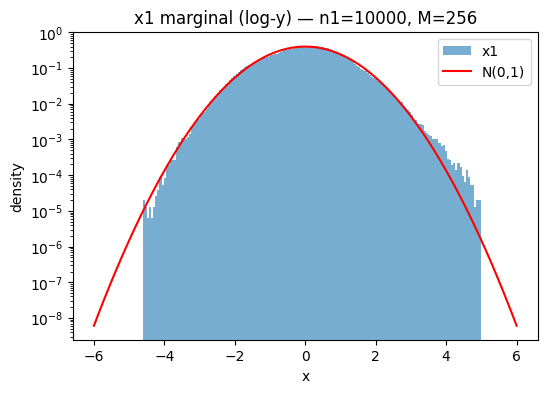

In [4]:
vals = x1.flatten().cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(vals, bins=200, range=(-6, 6), density=True, alpha=0.6, label='x1')
xx = np.linspace(-6, 6, 400)
ax.plot(xx, np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi), 'r-', label='N(0,1)')
ax.set_yscale('log'); ax.set_xlabel('x'); ax.set_ylabel('density'); ax.legend()
ax.set_title(f'x1 marginal (log-y) — n1={N1}, M={TARGET_LEN}')
plt.show()

## Example time series + scaling exponent ratio

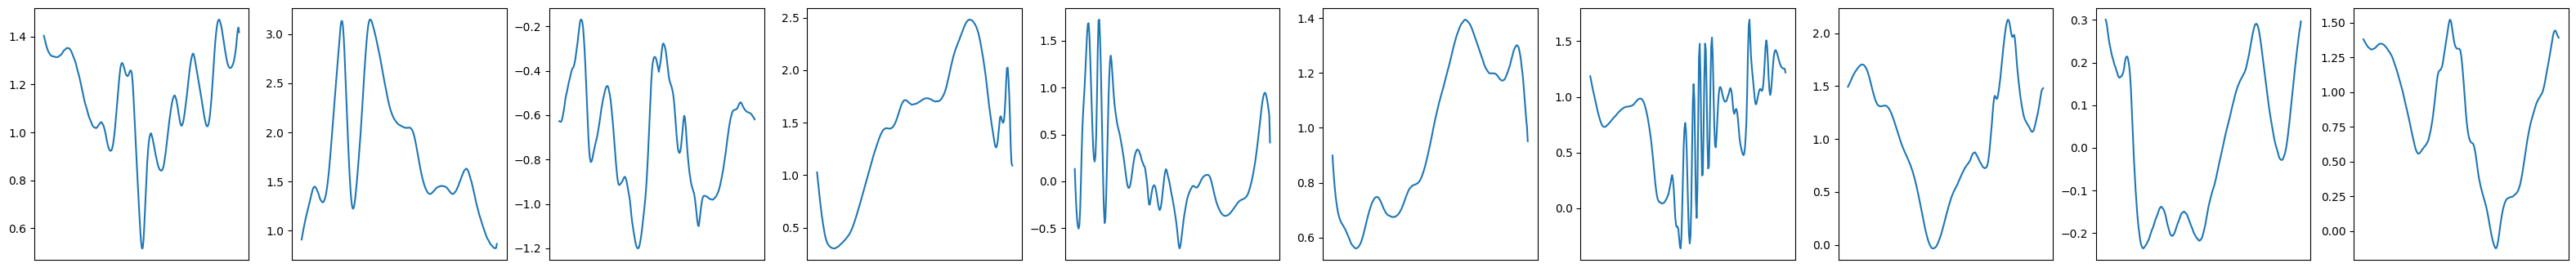

In [9]:
plot_time_series_row(x1, 10)

Computing structure functions for 24 lags...
Loaded structure functions from cache!


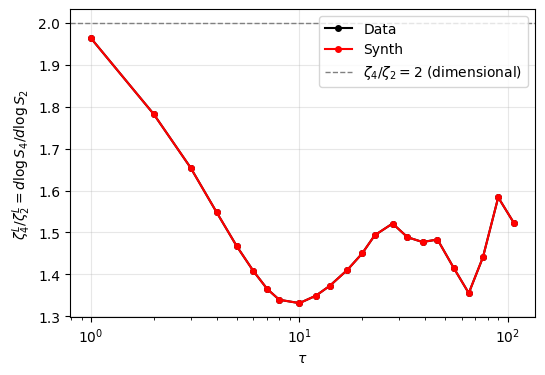

(array([  1,   2,   3,   4,   5,   6,   7,   8,  10,  12,  14,  17,  20,
         23,  28,  33,  39,  46,  55,  65,  76,  90, 107]),
 array([1.96346825, 1.78228556, 1.65500704, 1.54852364, 1.46734368,
        1.40843916, 1.36516513, 1.3393286 , 1.33130216, 1.34912277,
        1.37282284, 1.41083958, 1.44987093, 1.49352172, 1.52138939,
        1.4887512 , 1.4772182 , 1.48321302, 1.41560202, 1.35519885,
        1.44072316, 1.58384526, 1.52283771]),
 array([1.96346825, 1.78228556, 1.65500704, 1.54852364, 1.46734368,
        1.40843916, 1.36516513, 1.3393286 , 1.33130216, 1.34912277,
        1.37282284, 1.41083958, 1.44987093, 1.49352172, 1.52138939,
        1.4887512 , 1.4772182 , 1.48321302, 1.41560202, 1.35519885,
        1.44072316, 1.58384526, 1.52283771]))

In [6]:
scaling_exponent_ratio_compare(x1, x1, 30, kill_points=1)

## Filters built at (M, J, Q)

filters: (1, 9, 256)   (Q=1 bank, for L_6 and Scattering_*_Q1)
filters_Q: (1, 25, 256)   (Q=3 bank, for Scalar_psi/morlet)


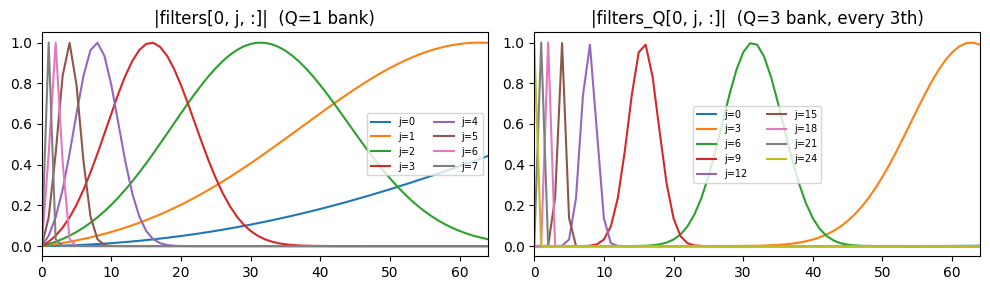

In [7]:
M = x1.shape[-1]
filters, filters_Phi = return_Filters(M, J, 1, device=device, include_phi=True)
filters_Q = return_Filters(M, J, Q, device=device)
print('filters:',   tuple(filters.shape),   '  (Q=1 bank, for L_6 and Scattering_*_Q1)')
print('filters_Q:', tuple(filters_Q.shape), f'  (Q={Q} bank, for Scalar_psi/morlet)')

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for j in range(J):
    axes[0].plot(filters[0, j, :].abs().cpu(), label=f'j={j}')
axes[0].set_title('|filters[0, j, :]|  (Q=1 bank)'); axes[0].set_xlim(0, M // 4); axes[0].legend(fontsize=7, ncol=2)
for j in range(0, filters_Q.shape[1], max(1, filters_Q.shape[1] // J)):
    axes[1].plot(filters_Q[0, j, :].abs().cpu(), label=f'j={j}')
axes[1].set_title(f'|filters_Q[0, j, :]|  (Q={Q} bank, every {max(1, filters_Q.shape[1] // J)}th)')
axes[1].set_xlim(0, M // 4); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## Potentials — exactly the set that will enter the Gram in the 30 seeds

Builds the dict, applies `--drop_stats` as `run_experiment` does, instantiates a minimal `SDE` object (which drives the fit the same way the real run will), and prints the final per-family counts. **No SDE evolution** — this is just the setup pass that happens at `t=0`.

If the counts and the layout above match your mental model, and the marginal / time-series / scaling plots look like turbulence should, the data and potential pipeline are in order and the 1-seed launch is safe to submit.

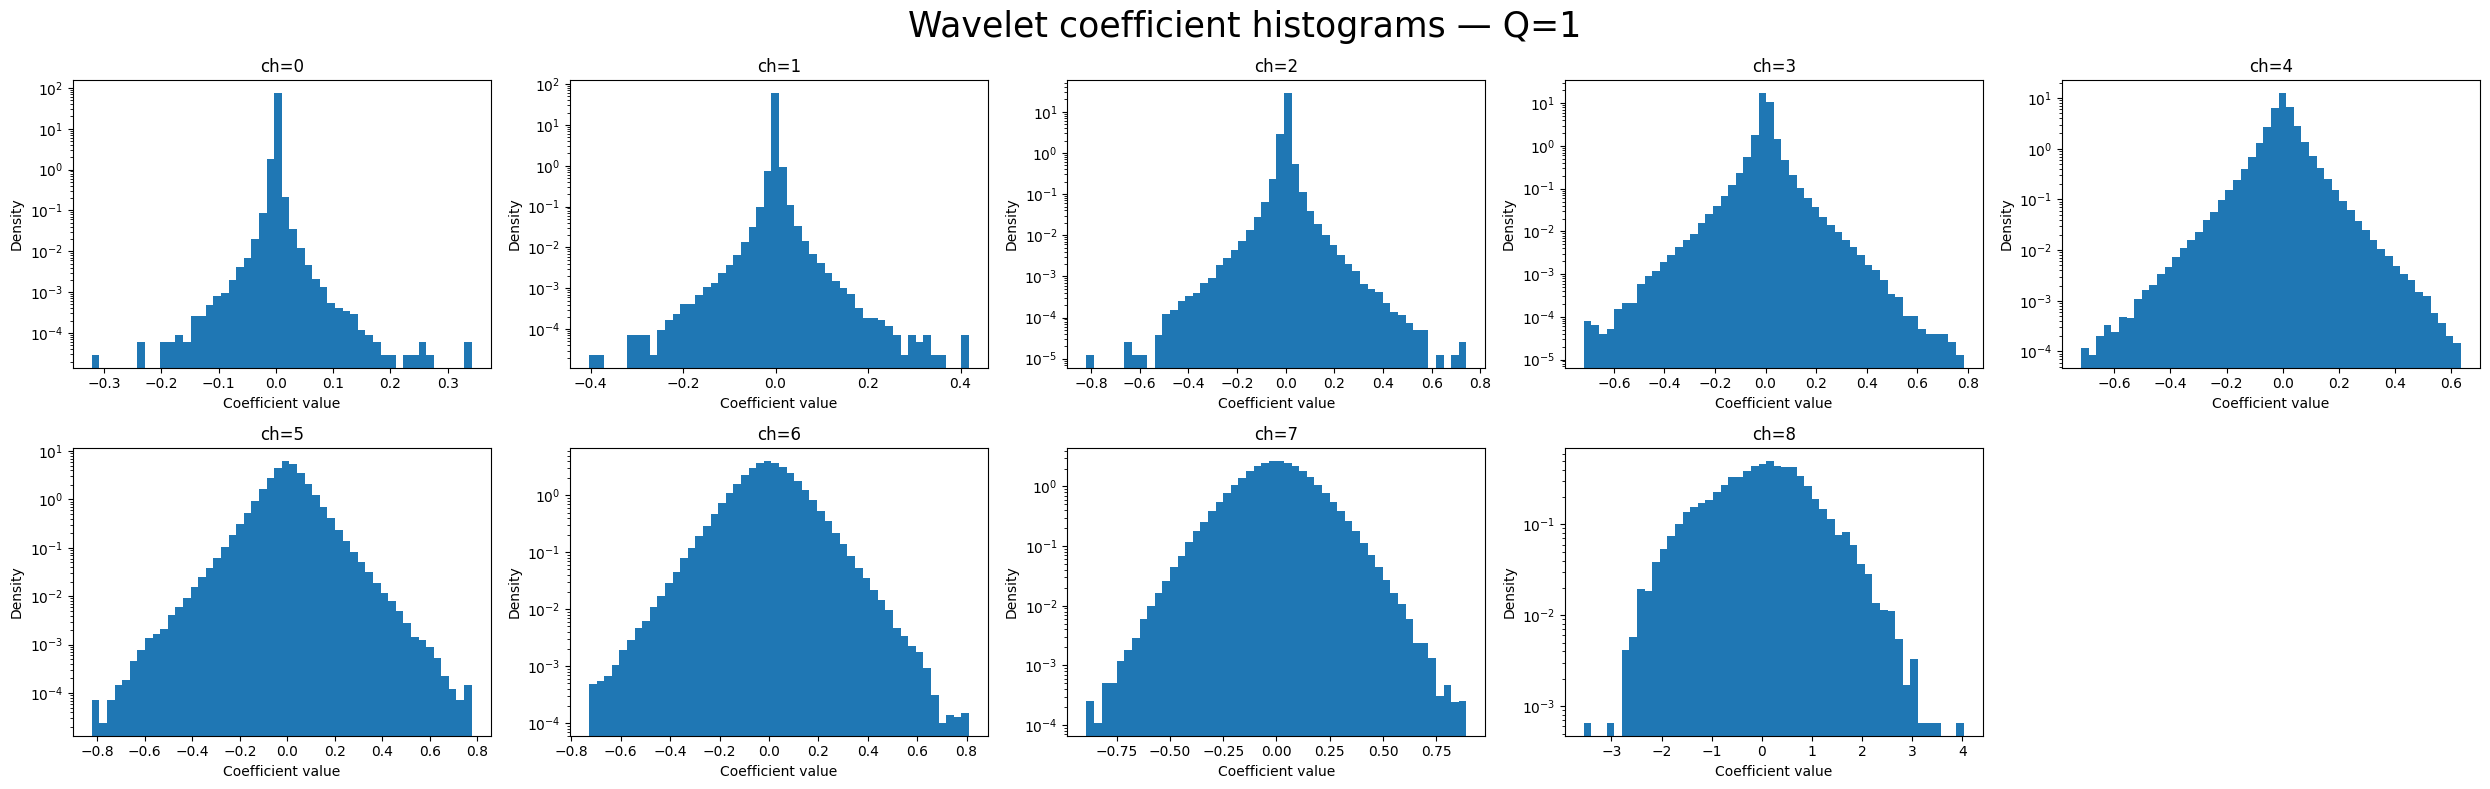

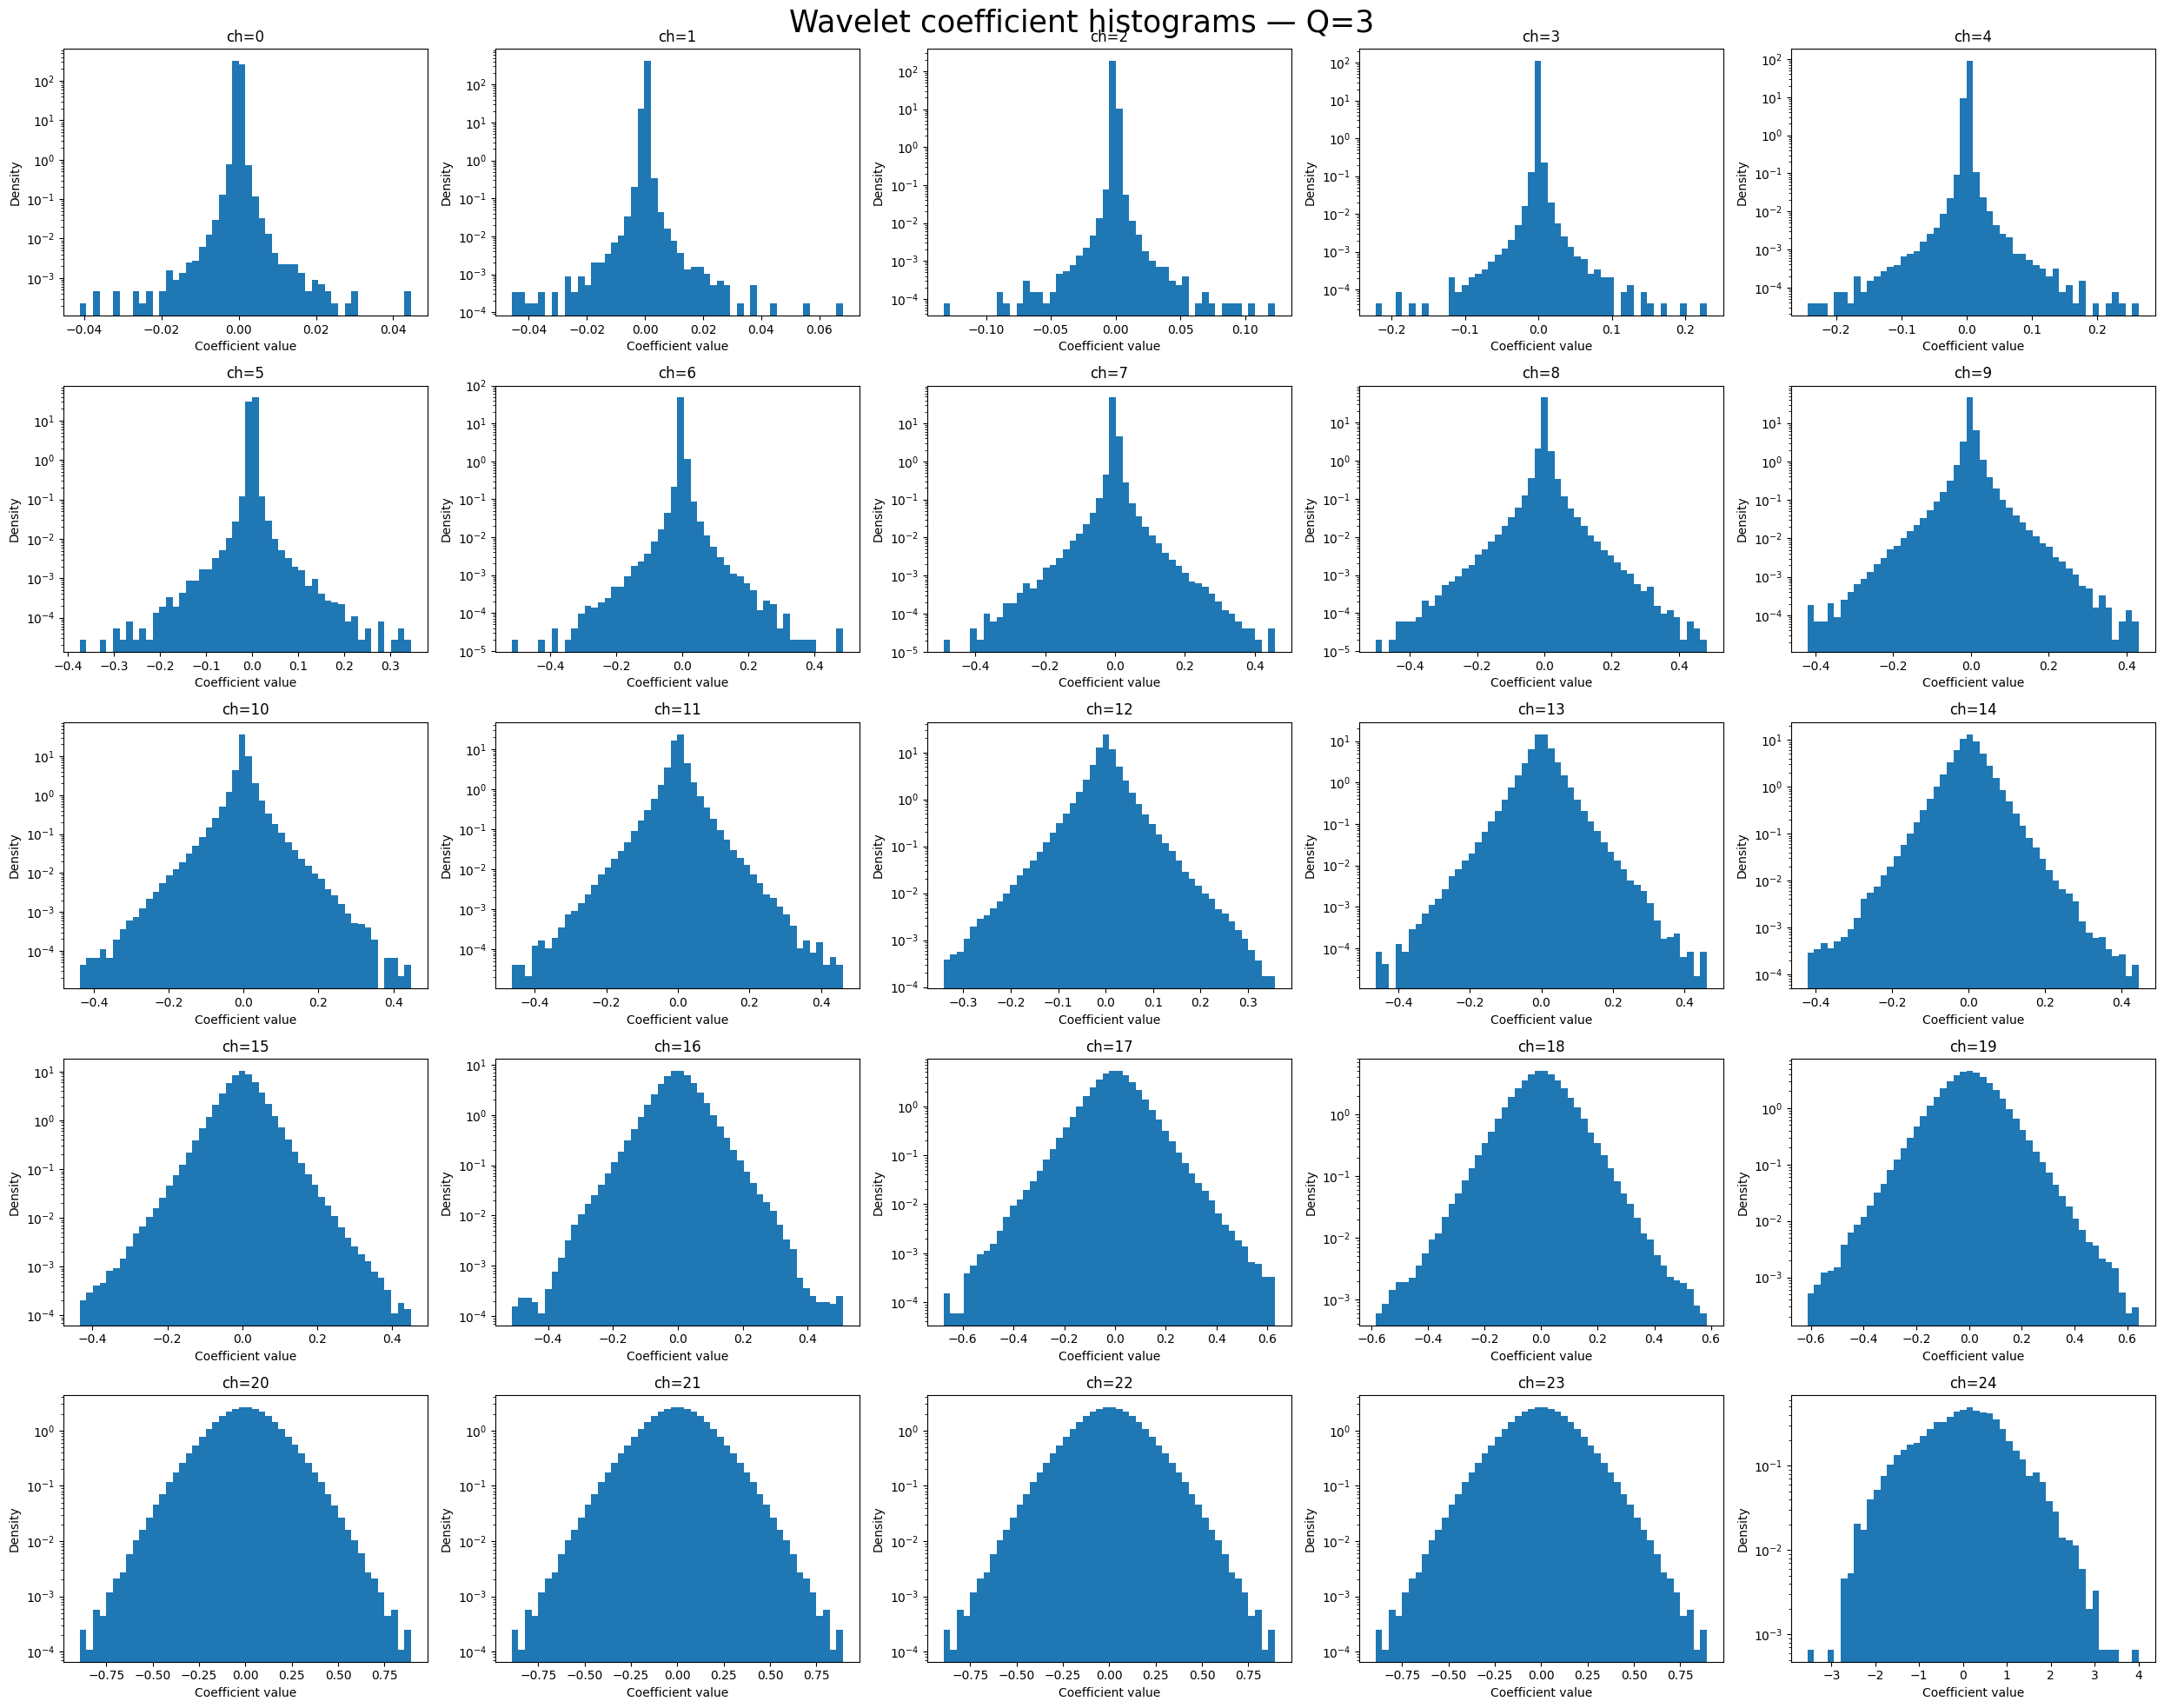

In [15]:
wt_Q = torch.fft.ifft(torch.fft.fft(x1) * filters_Q).real

def plot_wavelet_hists(wt, title):
    n = wt.shape[1]
    ncols = 5
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for i in range(n):
        vals = wt[:, i, :].detach().cpu().flatten().numpy()
        axes[i].hist(vals, bins=50, density=True, log=True)
        axes[i].set_title(f'ch={i}')
        axes[i].set_xlabel('Coefficient value'); axes[i].set_ylabel('Density')
    for k in range(n, len(axes)):
        axes[k].axis('off')
    plt.suptitle(title, fontsize=25); plt.tight_layout(); plt.show()

plot_wavelet_hists(wt_1, 'Wavelet coefficient histograms — Q=1')
plot_wavelet_hists(wt_Q, 'Wavelet coefficient histograms — Q=3')